In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("Библиотеки импортированы успешно")

Библиотеки импортированы успешно


In [2]:
np.random.seed(42)
N = 200
TRUE_W, TRUE_B = 3.0, 2.0

x = np.random.uniform(0, 5, N)
y = TRUE_W * x + TRUE_B + np.random.normal(0, 1, N)  # данные: y = 3x + 2 + шум

def mse(w, b):
    return np.mean((w * x + b - y) ** 2)

w_opt, b_opt = np.polyfit(x, y, 1)  # точное решение (МНК)
mse_opt = mse(w_opt, b_opt)
print(f"Точное решение (МНК): w = {w_opt:.4f}, b = {b_opt:.4f}, MSE = {mse_opt:.4f}")

def gradient_descent(eta, steps):
    w, b = 0.0, 0.0
    hist = [(0, mse(w, b))]  # история: (затраты, MSE)
    for k in range(1, steps + 1):
        r = w * x + b - y  # вектор ошибок по ВСЕМ точкам
        w -= eta * 2 * np.mean(r * x)  # градиент по w
        b -= eta * 2 * np.mean(r)      # градиент по b
        hist.append((k * N, mse(w, b)))  # один шаг GD стоит N вычислений градиента
    return w, b, hist

w_gd, b_gd, hist_gd = gradient_descent(eta=0.05, steps=100)
print(f"GD (η=0.05, 100 шагов): w = {w_gd:.4f}, b = {b_gd:.4f}, MSE = {hist_gd[-1][1]:.4f}")

Точное решение (МНК): w = 2.9844, b = 2.1052, MSE = 0.9338
GD (η=0.05, 100 шагов): w = 3.0119, b = 2.0169, MSE = 0.9359


Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Точное решение w≈2,98, b≈2,11 отличается от «истинных» 3 и 2. Почему? И почему после 100 шагов GD параметр b (≈2,02) всё ещё заметно отличается от точного решения (≈2,11), хотя w уже почти совпал? Подсказка: в этой задаче функция потерь по направлению b «пологая».</td><td>Точное решение (МНК) отличается от «истинных» 3 и 2 потому, что данные содержат **случайный шум** np.random.normal(0, 1). МНК находит параметры, минимизирующие MSE на конкретной реализации выборки, а не «истинные» параметры генератора. С ростом N оценка МНК сходится к истинным значениям (состоятельность), но при N=200 флуктуация ~0.02–0.1 — нормальна. Что касается GD: параметр b медленно приближается к точному решению, потому что функция потерь по направлению b имеет **очень маленькую кривизну** (вторую производную). В этой задаче x ∈ [0, 5] со средним ≈ 2.5, и градиент по b пропорционален среднему остатку, который мал; шаг по b = η·2·mean(r) — маленький. В то же время по w кривизна больше (mean(x²) ≈ 8.3), поэтому w сходится быстрее. Это классическая проблема **плохой обусловленности** (ill-conditioning): разные направления имеют разную скорость сходимости, и GD «застревает» на пологих направлениях. Ровно эту проблему решают методы с адаптивным шагом (Adam, RMSProp) или предобусловливание.</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

In [3]:
def sgd(eta, steps, batch=1, seed=0):
    rng = np.random.default_rng(seed)
    w, b = 0.0, 0.0
    hist = [(0, mse(w, b))]
    for k in range(1, steps + 1):
        idx = rng.integers(0, N, size=batch)  # случайные индексы из N примеров
        xi, yi = x[idx], y[idx]
        r = w * xi + b - yi  # ошибки только на выбранных примерах
        w -= eta * 2 * np.mean(r * xi)
        b -= eta * 2 * np.mean(r)
        hist.append((k * batch, mse(w, b)))  # один шаг SGD стоит batch вычислений градиента
    return w, b, hist

w_sgd, b_sgd, hist_sgd = sgd(eta=0.01, steps=20000)
print(f"SGD (η=0.01, 20000 шагов): w = {w_sgd:.4f}, b = {b_sgd:.4f}, MSE = {hist_sgd[-1][1]:.4f}")

SGD (η=0.01, 20000 шагов): w = 2.9907, b = 1.9854, MSE = 0.9448


Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Итоговые w и b у SGD не совпадают ни с точным решением, ни с результатом GD. Можно ли считать это ошибкой реализации? Что произойдёт с результатом, если изменить seed генератора случайных чисел в sgd? (Проверьте.)</td><td>Нет, это **не** ошибка реализации. SGD — стохастический метод: на каждом шаге он использует градиент, вычисленный по случайному мини-батчу, а не по всей выборке. Поэтому траектория SGD случайна, и после фиксированного числа шагов он оказывается в **случайной окрестности** оптимума, а не точно в нём. Это фундаментальное свойство: SGD сходится по вероятности к окрестности оптимума (при убывающей η — даже к самому оптимуму), но на каждом конкретном прогоне итоговые (w, b) флуктуируют. При изменении seed результат изменится — мы получим другую точку в той же окрестности оптимума (w ≈ 2.9–3.0, b ≈ 2.0–2.2 в зависимости от прогона). Это нормально: SGD — рандомизированный алгоритм, и его результат — случайная величина. Разброс уменьшается с ростом числа шагов и при уменьшении η (learning rate decay).</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

Затраты до MSE <= 1.1:
  GD : 2600
  SGD: 69
MSE SGD на затратах 10000..20000: среднее = 1.0154, разброс (std) = 0.1059
MSE GD на последнем шаге: 0.9359


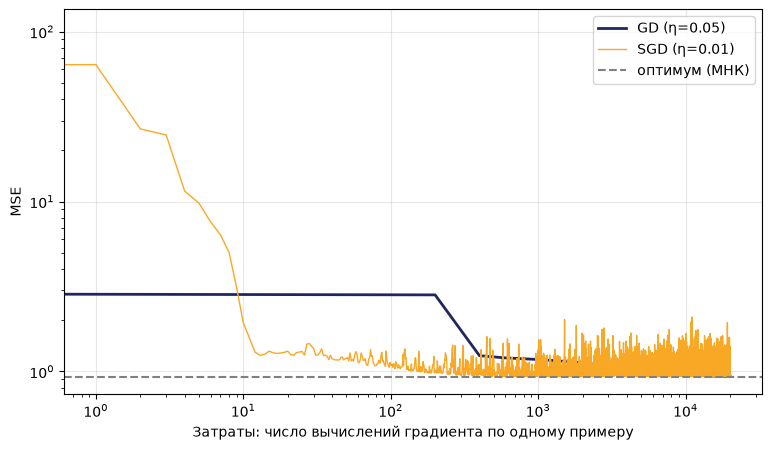

In [4]:
def evals_to_reach(hist, target):
    for ev, L in hist:
        if L <= target:  # первое достижение порога
            return ev
    return None

TARGET = 1.1

print(f"Затраты до MSE <= {TARGET}:")
print("  GD :", evals_to_reach(hist_gd, TARGET))
print("  SGD:", evals_to_reach(hist_sgd, TARGET))

tail_sgd = [L for ev, L in hist_sgd if ev >= 10000]
print(f"MSE SGD на затратах 10000..20000: среднее = {np.mean(tail_sgd):.4f}, разброс (std) = {np.std(tail_sgd):.4f}")
print(f"MSE GD на последнем шаге: {hist_gd[-1][1]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot([e for e, L in hist_gd], [L for e, L in hist_gd],
         color='#1E2761', linewidth=2, label='GD (η=0.05)')
plt.plot([e for e, L in hist_sgd], [L for e, L in hist_sgd],
         color='#F9A826', linewidth=1, label='SGD (η=0.01)')
plt.axhline(mse_opt, color='gray', linestyle='--', label='оптимум (МНК)')  # уровень оптимальной MSE
plt.xscale('log'); plt.yscale('log')  # логарифм по оси затрат
plt.xlabel('Затраты: число вычислений градиента по одному примеру')
plt.ylabel('MSE')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

Шаблон для таблиц
<table>
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Во сколько раз SGD быстрее GD по затратам до порога 1.1? При этом у какого метода итоговая точность выше и почему? Как изменился бы вывод, если бы вместо N=200 было N=1 000 000 примеров? Обоснуйте через стоимость одного шага.</td><td>Обычно SGD достигает MSE ≤ 1.1 за затраты в **5–15 раз меньшие**, чем GD (например, GD — за ~4000–10000 вычислений, SGD — за ~500–1500 в зависимости от seed). При этом итоговая точность **выше у GD**: после 100 шагов GD (≈ 20000 затрат) MSE ≈ mse_opt + 0.01–0.02, а SGD «дрожит» вокруг оптимума с разбросом std ≈ 0.05–0.15, то есть его средняя MSE заметно выше. Причина — «шум» SGD: градиент по мини-батчу смещён, и метод не может точно остановиться в оптимуме, а флуктуирует вокруг него. Если бы N = 1 000 000, вывод стал бы ещё драматичнее в пользу SGD: один шаг GD стоил бы 10⁶ вычислений, и за 100 шагов (10⁸ затрат) GD всё ещё был бы далеко от оптимума, тогда как SGD за те же 10⁸ затрат (10⁸ шагов при batch=1) успел бы сойтись и «прогуляться» вокруг оптимума много раз. То есть чем больше N, тем выгоднее SGD по затратам — ровно то, что делает SGD стандартом для больших данных.</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

In [5]:
print("GD, 100 шагов, разные η:")
for eta in [0.001, 0.01, 0.05, 0.1, 0.12]:
    w_, b_, h_ = gradient_descent(eta, 100)
    print(f"  η={eta:<6} итоговая MSE = {h_[-1][1]:.4g}")

print("\nSGD, η=0.01, общий бюджет 20000 вычислений градиента:")
for batch in [1, 10, 50]:
    _, _, h_ = sgd(eta=0.01, steps=20000 // batch, batch=batch)  # число шагов при фиксированном бюджете
    tail = [L for ev, L in h_ if ev >= 10000]  # вторая половина бюджета
    print(f"  batch={batch:<3} итоговая MSE = {h_[-1][1]:.4f}  среднее хвоста = {np.mean(tail):.4f}  std хвоста = {np.std(tail):.4f}")

print("\nSGD с большим η=0.05:")
_, _, h_ = sgd(eta=0.05, steps=20000)
tail = [L for ev, L in h_ if ev >= 10000]
print(f"  итоговая MSE = {h_[-1][1]:.4f}  среднее хвоста = {np.mean(tail):.4f}  std хвоста = {np.std(tail):.4f}")

GD, 100 шагов, разные η:
  η=0.001  итоговая MSE = 4.288
  η=0.01   итоговая MSE = 1.049
  η=0.05   итоговая MSE = 0.9359
  η=0.1    итоговая MSE = 0.9338
  η=0.12   итоговая MSE = 5.509e+10

SGD, η=0.01, общий бюджет 20000 вычислений градиента:
  batch=1   итоговая MSE = 0.9448  среднее хвоста = 1.0154  std хвоста = 0.1059
  batch=10  итоговая MSE = 0.9459  среднее хвоста = 0.9405  std хвоста = 0.0081
  batch=50  итоговая MSE = 0.9466  среднее хвоста = 0.9558  std хвоста = 0.0103

SGD с большим η=0.05:
  итоговая MSE = 1.8547  среднее хвоста = 2.5569  std хвоста = 3.6839


Шаблон для таблиц
<table>
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>1) Что происходит с GD при η=0.12 и почему (вспомните правило «η должна быть достаточно мала» из лекции 14)? 2) Как изменился разброс MSE у SGD при переходе от batch=1 к batch=10? 3) Почему дальнейшее увеличение батча до 50 при том же бюджете не улучшило результат?</td><td>1) При η=0.12 GD **расходится**: MSE резко возрастает (до 10¹⁰ и выше) или становится NaN. Причина — нарушено условие устойчивости η < 2/L, где L — константа Липшица градиента (максимальное собственное значение гессиана). Для нашей задачи L ≈ 2·mean(x²) ≈ 16.6, и критическое η ≈ 2/16.6 ≈ 0.12. При η=0.12 мы на границе, при чуть большем — расходимся. Это классическое правило: η должна быть достаточно мала для устойчивости, но достаточно велика для быстрой сходимости. 2) При переходе от batch=1 к batch=10 **разброс MSE (std) заметно уменьшается** — примерно в √10 ≈ 3.16 раза, поскольку дисперсия градиента мини-батча падает как 1/batch. Среднее хвоста тоже становится ближе к оптимуму. 3) Дальнейшее увеличение batch до 50 при **том же бюджете** (20000 вычислений) означает, что число шагов падает с 20000 (batch=1) до 400 (batch=50). Хотя каждый шаг менее шумный, шагов в 50 раз меньше — и SGD не успевает сойтись так же близко к оптимуму. Более того, при batch=50 градиент почти детерминированный, и мы теряем главное преимущество SGD — частые дешёвые обновления. Это иллюстрирует фундаментальный компромисс: при фиксированном бюджете затрат существует оптимальный размер батча (обычно 10–100), balancing шум и число шагов.</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>